# **MemFlow : Inférence du flux optique**

Utilisation du modèle MemFlow pré-entraîné (Dong & Fu, MemFlow: Optical Flow Estimation and Prediction with Memory, CVPR 2024).

**Uniquement de l'inférence, sans réentraînement du modèle.**

Section	Résultats obtenus

Code source officiel : https://github.com/DQiaole/MemFlow


| Section | Résultats obtenus |
|---|---|
| 6 | Flux optique pour chaque paire d'images, **temps d'exécution par paire**, **mémoire GPU maximale** et nombre de paramètres du modèle. |
| 7 | Vidéo comparative, flux optique représenté en couleurs, **cartes thermiques de magnitude** et champs de vecteurs. |
| 8 | **Carte thermique de l'attention appliquée à la mémoire**, montrant les informations auxquelles MemFlow prête attention. |
| 9 | Étude des itérations du GRU : évolution du flux optique étape par étape et compromis entre vitesse et qualité. |
| 10 | Comparaison du modèle **avec et sans mémoire** sur notre vidéo. |
| 11 | Évaluation avec les métriques **EPE / Fl-all** sur le benchmark Middlebury, qui fournit une vérité terrain (notre vidéo n'en possède pas). |
| 12 | Sauvegarde de tous les résultats dans `MyDrive/flow_optique/memflow/`, avec une archive ZIP contenant les principaux résultats à partager pour leur interprétation. |


## **Monter Google Drive**
Connecte Google Drive à Colab. On y lit la vidéo et on y sauvegarde les résultats.

In [22]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## **Vérifier le GPU**
Affiche la version de PyTorch et vérifie qu'un GPU CUDA est disponible.

In [23]:
import torch
print("torch", torch.__version__, "| CUDA available:", torch.cuda.is_available())
assert torch.cuda.is_available(), "No GPU: Runtime > Change runtime type > GPU"
GPU_NAME = torch.cuda.get_device_name(0)
print(GPU_NAME)
DEVICE = "cuda"

torch 2.14.1+cu130 | CUDA available: True
Tesla T4


## **Paramètres de la vidéo et du prétraitement**

In [24]:
VIDEO_PATH = "/content/drive/MyDrive/Analyse Video/presentation flow motion PROJET1/video voiture 7s.mp4"
START_SEC = 0          # le début du segment
DURATION_SEC = 10      # > duree reelle (7 s) -> toute la video est traitee
MAX_WIDTH = 640        # limite la largeur des images afin de maîtriser la consommation mémoire GPU
TARGET_FPS = 0         # la fréquence d’origine est conservée
USE_DRIVE = True


On sélectionne la variante du réseau (MemFlowNet), le checkpoint pré-entraîné correspondant au domaine Sintel, et le nombre d’itérations de raffinement (ITERS=15). Un checkpoint contient les poids appris pendant l’entraînement : ici, on les charge pour faire de l’inférence, sans réentraîner le modèle. SAVE_RAW_FLOW active la sauvegarde des champs de flux bruts. Les noms de fichier et étiquettes de sortie sont construits automatiquement.

In [25]:
MODEL = "MemFlowNet"
CHECKPOINT_STAGE = "sintel"
ITERS = 15
SAVE_RAW_FLOW = True
CKPT_NAME = f"{MODEL}_{CHECKPOINT_STAGE}.pth"
TAG = f"memflow"
print("Model:", MODEL, "| checkpoint:", CKPT_NAME, "| iterations:", ITERS)

Model: MemFlowNet | checkpoint: MemFlowNet_sintel.pth | iterations: 15


On définit le dossier de sortie (pour enregistrer les résultats finales)

In [26]:
import os
if USE_DRIVE:
    if not os.path.exists("/content/drive/MyDrive"):
        from google.colab import drive
        drive.mount("/content/drive")
    SAVE_ROOT = "/content/drive/MyDrive/Analyse Video/presentation flow motion PROJET1/flow_optique"
else:
    SAVE_ROOT = "/content/flow_optique"
os.makedirs(SAVE_ROOT, exist_ok=True)
print("Results folder:", SAVE_ROOT)


Results folder: /content/drive/MyDrive/Analyse Video/presentation flow motion PROJET1/flow_optique


## **Configuration du modèle MemFlow**

On installe les bibliothèques Python nécessaires au projet : configuration (yacs), journalisation (loguru), opérations tensorielle (einops), composants de modèles (timm) et utilitaires de téléchargement. Puis on récupère le dépôt officiel MemFlow depuis GitHub s’il n’est pas déjà présent. Le code source contient l’architecture du réseau, les fonctions d’inférence et les configurations.

In [27]:
!pip -q install yacs loguru einops timm yt-dlp gdown
import os
if not os.path.exists("/content/drive/MyDrive/Analyse Video/presentation flow motion PROJET1/MemFlow"):
    !git clone -q https://github.com/DQiaole/MemFlow.git /content/MemFlow

fatal: destination path '/content/MemFlow' already exists and is not an empty directory.


On crée le dossier ckpts, puis vérifie si le fichier de poids demandé est déjà disponible. Sinon, elle interroge l’API GitHub des releases MemFlow, recherche l’asset dont le nom correspond à CKPT_NAME et le télécharge. Le checkpoint est ensuite vérifié par son existence et sa taille.

In [28]:
import json, urllib.request
os.makedirs("/content/drive/MyDrive/Analyse Video/presentation flow motion PROJET1/MemFlow/ckpts", exist_ok=True)
ckpt_path = f"/content/drive/MyDrive/Analyse Video/presentation flow motion PROJET1/MemFlow/ckpts/{CKPT_NAME}"
if not os.path.exists(ckpt_path):
    api = "https://api.github.com/repos/DQiaole/MemFlow/releases/tags/v1.0.0"
    assets = json.load(urllib.request.urlopen(api))["assets"]
    match = [a for a in assets if a["name"] == CKPT_NAME]
    assert match, f"{CKPT_NAME} not found. Available: {[a['name'] for a in assets]}"
    print("Downloading", CKPT_NAME, f"({match[0]['size']/1e6:.0f} MB)")
    urllib.request.urlretrieve(match[0]["browser_download_url"], ckpt_path)
print("OK:", ckpt_path, f"{os.path.getsize(ckpt_path)/1e6:.0f} MB")

OK: /content/drive/MyDrive/Analyse Video/presentation flow motion PROJET1/MemFlow/ckpts/MemFlowNet_sintel.pth 25 MB


## **Vérification et identification de la vidéo**

On vérifie que le fichier vidéo défini par VIDEO_PATH existe et n’est pas vide. Puis, on lit les métadonnées du flux vidéo : largeur, hauteur, fréquence d’images et durée.

In [47]:
import os, shutil, subprocess, glob
if not (os.path.exists(VIDEO_PATH) and os.path.getsize(VIDEO_PATH) > 0):
    cands = glob.glob("/content/drive/MyDrive/Analyse Video/presentation flow motion PROJET1/*voiture*") + glob.glob("/content/drive/MyDrive/Analyse Video/presentation flow motion PROJET1/*voiture*") + glob.glob("/*voiture*")
    cands = [c for c in cands if c.lower().endswith((".mp4", ".mov", ".avi", ".mkv"))]
    assert cands, f"Video not found at {VIDEO_PATH!r}. Upload it (Files panel) or fix VIDEO_PATH."
    print(f"[!] {VIDEO_PATH!r} introuvable, j'utilise : {cands[0]!r}")
    VIDEO_PATH = cands[0]
print("Video:", VIDEO_PATH, f"({os.path.getsize(VIDEO_PATH)/1e6:.1f} MB)")
print(subprocess.run(["ffprobe", "-v", "error", "-select_streams", "v:0", "-show_entries",
                      "stream=width,height,r_frame_rate,duration", "-of", "default=nw=1", VIDEO_PATH],
                     check=True, capture_output=True, text=True).stdout)


Video: /content/drive/MyDrive/Analyse Video/presentation flow motion PROJET1/video voiture 7s.mp4 (0.6 MB)
width=576
height=1024
r_frame_rate=30/1
duration=7.066667



On découpe la vidéo en images JPG avec `ffmpeg`. Puis:
- On réduit la largeur à `MAX_WIDTH` pour économiser la mémoire GPU.
- On garde le FPS d'origine, sauf si `TARGET_FPS` est défini, auquel cas elle saute des images.
- On lit le FPS réel, la taille et le nombre d'images, puis les enregistre dans `clip_info.json`.
- On définit `load_rgb(i)`, qui charge l'image `i` en RGB.

In [48]:
import glob, json, cv2
WORK = "/content/drive/MyDrive/Analyse Video/presentation flow motion PROJET1/work"
FRAMES = f"{WORK}/frames"
shutil.rmtree(FRAMES, ignore_errors=True); os.makedirs(FRAMES)

vf = []
if TARGET_FPS and TARGET_FPS > 0:
    vf.append(f"fps={TARGET_FPS}")
vf.append(f"scale='min({MAX_WIDTH},iw)':-2")
subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-ss", str(START_SEC), "-i", VIDEO_PATH,
                "-t", str(DURATION_SEC), "-vf", ",".join(vf), "-qscale:v", "2",
                f"{FRAMES}/frame_%05d.jpg"], check=True)

def probe_fps(path):
    out = subprocess.check_output(["ffprobe", "-v", "0", "-select_streams", "v:0",
                                   "-show_entries", "stream=r_frame_rate", "-of", "csv=p=0", path]).decode().strip()
    if "/" in out:
        n, d = out.split("/"); return float(n) / float(d)
    return float(out)

FPS = TARGET_FPS if (TARGET_FPS and TARGET_FPS > 0) else probe_fps(VIDEO_PATH)
frame_files = sorted(glob.glob(f"{FRAMES}/*.jpg"))
H0, W0 = cv2.imread(frame_files[0]).shape[:2]
N_FRAMES = len(frame_files)
assert N_FRAMES >= 3, "Need at least 3 frames"
CLIP_INFO = dict(start_sec=START_SEC, duration_sec=DURATION_SEC, max_width=MAX_WIDTH, target_fps=TARGET_FPS,
                 fps=FPS, n_frames=N_FRAMES, width=W0, height=H0)
json.dump(CLIP_INFO, open(f"{SAVE_ROOT}/clip_info.json", "w"), indent=1)
print(f"{N_FRAMES} frames, {W0}x{H0}, {FPS:.2f} fps -> {N_FRAMES-1} flow fields to estimate")

def load_rgb(i):
    return cv2.cvtColor(cv2.imread(frame_files[i]), cv2.COLOR_BGR2RGB)

212 frames, 576x1024, 30.00 fps -> 211 flow fields to estimate


On définit des fonctions réutilisées dans les expériences.
* **warp_back** applique le flux estimé pour échantillonner l’image suivante aux positions correspondantes et renvoie aussi un masque des pixels valides.
* **photometric_error** compare en niveaux de gris l’image courante à l’image suivante recalée: c’est un indicateur indirect, pas une vérité terrain.

* **read_flo** lit le format Middlebury .flo. flow_metrics calcule l’EPE et le taux Fl-all en ignorant les valeurs de vérité terrain invalides.

* Les deux dernières fonctions dessinent une carte de magnitude et un champ de vecteurs.

* **get_middlebury** télécharge et prépare les séquences du benchmark avec leurs flux de référence.

In [31]:
import numpy as np, matplotlib.pyplot as plt
import cv2

def warp_back(img_next, flow):
    h, w = flow.shape[1:]
    gx, gy = np.meshgrid(np.arange(w, dtype=np.float32), np.arange(h, dtype=np.float32))
    mx, my = gx + flow[0].astype(np.float32), gy + flow[1].astype(np.float32)
    warped = cv2.remap(img_next, mx, my, cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=0)
    valid = (mx >= 0) & (mx <= w - 1) & (my >= 0) & (my <= h - 1)
    return warped, valid

def photometric_error(img_t, img_next, flow):
    g0 = cv2.cvtColor(img_t, cv2.COLOR_RGB2GRAY).astype(np.float32)
    g1 = cv2.cvtColor(img_next, cv2.COLOR_RGB2GRAY).astype(np.float32)
    warped, valid = warp_back(g1, flow)
    return float(np.abs(g0 - warped)[valid].mean()), float(np.abs(g0 - g1).mean())

def read_flo(path):
    with open(path, "rb") as f:
        assert np.fromfile(f, np.float32, 1)[0] == 202021.25, "bad .flo file"
        w, h = np.fromfile(f, np.int32, 2)
        return np.fromfile(f, np.float32, 2 * w * h).reshape(h, w, 2)

def flow_metrics(pred, gt):
    valid = (np.abs(gt) < 1e9).all(-1)
    epe = np.linalg.norm(pred - gt, axis=-1)[valid]
    mag = np.linalg.norm(gt, axis=-1)[valid]
    return float(epe.mean()), float(100 * ((epe > 3) & (epe / np.maximum(mag, 1e-6) > 0.05)).mean())

def magnitude_heatmap(ax, flow, title, vmax=None):
    mag = np.linalg.norm(flow, axis=0)
    im = ax.imshow(mag, cmap="inferno", vmin=0, vmax=vmax or np.percentile(mag, 99.5))
    ax.set_title(title); ax.axis("off")
    plt.colorbar(im, ax=ax, fraction=0.03, label="|flow| (px)")

def quiver_overlay(ax, img, flow, step=24, title=""):
    h, w = flow.shape[1:]
    ys, xs = np.mgrid[step // 2:h:step, step // 2:w:step]
    ax.imshow(img); ax.axis("off"); ax.set_title(title)
    ax.quiver(xs, ys, flow[0, ys, xs], flow[1, ys, xs], color="yellow", angles="xy",
              scale_units="xy", scale=0.5, width=0.002)

MIDDLEBURY_SEQS = ["Dimetrodon", "Grove2", "Grove3", "Hydrangea", "RubberWhale", "Urban2", "Urban3", "Venus"]

def get_middlebury(root="/content/drive/MyDrive/Analyse Video/presentation flow motion PROJET1/middlebury"):
    if not os.path.exists(f"{root}/other-gt-flow"):
        os.makedirs(root, exist_ok=True)
        for z in ["other-gt-flow.zip", "other-color-allframes.zip"]:
            subprocess.run(["wget", "-q", "-O", f"{root}/{z}", f"https://vision.middlebury.edu/flow/data/comp/zip/{z}"], check=True)
            subprocess.run(["unzip", "-q", "-o", f"{root}/{z}", "-d", root], check=True)
    seqs = {}
    for s in MIDDLEBURY_SEQS:
        frames = sorted(glob.glob(f"{root}/other-data/{s}/frame*.png"))
        frames = [f for f in frames if int(os.path.basename(f)[5:7]) <= 11]
        seqs[s] = dict(frames=frames, gt=read_flo(f"{root}/other-gt-flow/{s}/flow10.flo"))
    return seqs

On définit `GpuTimer`, qui mesure le temps d'exécution en millisecondes. Il synchronise le GPU avant et après pour obtenir une mesure exacte. `WARMUP` fixe le nombre de premières paires ignorées dans les moyennes.

In [32]:
import time
import torch

class GpuTimer:
    def __enter__(self):
        torch.cuda.synchronize(); self.t0 = time.perf_counter(); return self
    def __exit__(self, *a):
        torch.cuda.synchronize(); self.ms = 1000 * (time.perf_counter() - self.t0)

WARMUP = 3

## **Construction et chargement du réseau MemFlow**

On ajoute le dépôt aux chemins d’import Python, puis importe l’architecture, les fonctions de corrélation, le remplissage des images et les modules d’inférence. La configuration est choisie en fonction du modèle et du domaine (things, sintel ou kitti).

 **build_network** construit le réseau
  
  **torch.load** lit le checkpoint  
  
  **load_state_dict(..., strict=True)** charge les poids en vérifiant la correspondance des paramètres.
  
  Le modèle est transféré sur le GPU et placé en mode évaluation avec eval(). N_PARAMS compte ses paramètres.
  La cellule affiche aussi le temps de chargement, le coefficient appris de contribution mémoire et la limite de mémoire temporelle configurée.

In [33]:
import sys, importlib
REPO = "/content/drive/MyDrive/Analyse Video/presentation flow motion PROJET1/MemFlow"
os.chdir(REPO)
for p in [f"{REPO}/core", REPO]:
    if p not in sys.path:
        sys.path.insert(0, p)

from core.Networks import build_network
from core.Networks.MemFlowNet.corr import CorrBlock
from core.utils.utils import InputPadder
from core.utils import flow_viz
from inference import inference_core_skflow as inference_core
import inference.memory_manager_skflow as mm

CFG_MODULES = {("MemFlowNet", "things"): "configs.things_memflownet",
               ("MemFlowNet", "sintel"): "configs.sintel_memflownet",
               ("MemFlowNet", "kitti"): "configs.kitti_memflownet",
               ("MemFlowNet_T", "things"): "configs.things_memflownet_t",
               ("MemFlowNet_T", "sintel"): "configs.sintel_memflownet_t",
               ("MemFlowNet_T", "kitti"): "configs.kitti_memflownet_t"}
cfg = importlib.import_module(CFG_MODULES[(MODEL, CHECKPOINT_STAGE)]).get_cfg()
cfg.update(dict(name=MODEL, stage=CHECKPOINT_STAGE, restore_ckpt=ckpt_path))
cfg.val_decoder_depth = ITERS

t_load = time.perf_counter()
model = build_network(cfg)
ckpt = torch.load(ckpt_path, map_location="cpu", weights_only=False)
state = ckpt["model"] if "model" in ckpt else ckpt
state = {k.replace("module.", "", 1): v for k, v in state.items()}
model.load_state_dict(state, strict=True)
model = model.to(DEVICE).eval()
torch.cuda.synchronize()
LOAD_TIME_S = time.perf_counter() - t_load

N_PARAMS = sum(p.numel() for p in model.parameters())
print(f"Parameters: {N_PARAMS/1e6:.2f} M | load time {LOAD_TIME_S:.1f}s")
print("Learned memory weight alpha (Eq. 3, initialised at 0):", float(model.update_block.aggregator.gamma))
print("Flash-attention available:", mm.FLASH_AVAIABLE)
print("Max memory length l_max = max_mid_term_frames - 1 =", cfg.max_mid_term_frames - 1)

MemFlowNet_skflow
[Using basicencoder as context encoder]
[Using basicencoder as feature encoder]
[Using GMA-SK2]
[Using corr_fn default]
Parameters: 6.27 M | load time 0.4s
Learned memory weight alpha (Eq. 3, initialised at 0): -0.4330005645751953
Flash-attention available: False
Max memory length l_max = max_mid_term_frames - 1 = 1


Le patch de _readout conserve les poids d’attention (affinity) pour pouvoir les visualiser ensuite, tout en gardant le calcul original v @ affinity. Le drapeau CAPTURE active cette capture uniquement pour la paire choisie. memflow_step exécute une paire d’images : encodage du contexte et des caractéristiques, construction du volume de corrélation, lecture de la mémoire, puis mises à jour itératives du flux par le bloc GRU. Lorsque nécessaire, les caractéristiques de la paire sont ajoutées à la mémoire. make_pair convertit les images en tenseurs, les place sur le GPU, les complète aux dimensions compatibles et normalise les pixels dans [-1, 1]. run_sequence parcourt les paires, mesure le temps, peut enregistrer les flux et les états intermédiaires, et permet de désactiver la mémoire pour les expériences comparatives. FrameList charge les images à la demande, ce qui évite de garder toute la vidéo en mémoire GPU. Le décorateur torch.no_grad() désactive le calcul des gradients, inutile en inférence.

In [34]:
import sys, os
if "/content/drive/MyDrive/Analyse Video/presentation flow motion PROJET1/MemFlow" not in sys.path:
    sys.path.insert(0, "/content/drive/MyDrive/Analyse Video/presentation flow motion PROJET1/MemFlow")
import inference.memory_manager_skflow as mm
from core.utils.utils import InputPadder
import cv2
import torch

CAPTURE = {"on": False, "affinity": None}

def _readout_capture(self, affinity, v):
    if CAPTURE["on"]:
        CAPTURE["affinity"] = affinity[0].detach()
    return v @ affinity

mm.MemoryManager._readout = _readout_capture

@torch.no_grad()
def memflow_step(proc, images, end=False, record_iters=False):
    proc.curr_ti += 1
    is_mem_frame = (proc.curr_ti - proc.last_mem_ti >= proc.mem_every) and (not end)
    m = proc.model
    query, key, net, inp = m.encode_context(images[:, 0, ...])
    coords0, coords1, fmaps = m.encode_features(images)
    corr_fn = CorrBlock(fmaps[:, 0, ...], fmaps[:, 1, ...], num_levels=4, radius=4)
    per_iter = []
    for _ in range(proc.config.val_decoder_depth):
        coords1 = coords1.detach()
        corr = corr_fn(coords1)
        flow = coords1 - coords0
        motion_features, current_value = m.update_block.get_motion_and_value(flow, corr)
        readout = proc.memory.match_memory(query, key, current_value, scale=m.att.scale)
        motion_global = motion_features + m.update_block.aggregator.gamma * readout
        net, up_mask, delta_flow = m.update_block(net, inp, motion_features, motion_global)
        coords1 = coords1 + delta_flow
        if record_iters:
            per_iter.append(m.upsample_flow(coords1 - coords0, up_mask))
    flow_up = m.upsample_flow(coords1 - coords0, up_mask)
    if is_mem_frame:
        proc.memory.add_memory(key, current_value)
        proc.last_mem_ti = proc.curr_ti
    return flow_up, per_iter

h_init, w_init = cv2.imread(frame_files[0]).shape[:2]
padder = InputPadder((1, 2, 3, h_init, w_init))

def make_pair(img_a, img_b, pdr):
    x = torch.stack([torch.from_numpy(img_a), torch.from_numpy(img_b)]).permute(0, 3, 1, 2).float()[None]
    x = pdr.pad(x.to(DEVICE))
    return 2 * (x / 255.0) - 1.0

def run_sequence(images_rgb, use_memory=True, iters=ITERS, n_pairs=None, record_iters_at=None,
                 capture_at=None, keep=True, on_pair=None):
    cfg.val_decoder_depth = iters
    proc = inference_core.InferenceCore(model, config=cfg)
    pdr = InputPadder((1, 2, 3, *images_rgb[0].shape[:2]))
    n = len(images_rgb) - 1 if n_pairs is None else n_pairs
    flows, times, extra = [], [], {}
    for ti in range(n):
        if not use_memory:
            proc.clear_memory()
        a, b = images_rgb[ti], images_rgb[ti + 1]
        CAPTURE["on"] = (capture_at == ti)
        with GpuTimer() as t:
            pair = make_pair(a, b, pdr)
            flow_up, per_iter = memflow_step(proc, pair, end=(ti == n - 1), record_iters=(record_iters_at == ti))
            flow = pdr.unpad(flow_up[0]).float().cpu().numpy()
        CAPTURE["on"] = False
        times.append(t.ms)
        if per_iter:
            extra["per_iter"] = [pdr.unpad(f[0]).cpu().numpy() for f in per_iter]
        if capture_at == ti:
            a_ = CAPTURE["affinity"]
            extra["affinity"] = None if a_ is None else a_.float().cpu()   # copie CPU une seule fois, hors chrono
            CAPTURE["affinity"] = None
        if on_pair:
            on_pair(ti, flow)
        if keep:
            flows.append(flow.astype(np.float16))
    cfg.val_decoder_depth = ITERS
    return flows, np.array(times), extra

class FrameList:
    def __init__(self, files): self.files = files
    def __len__(self): return len(self.files)
    def __getitem__(self, i): return cv2.cvtColor(cv2.imread(self.files[i]), cv2.COLOR_BGR2RGB)
VIDEO_FRAMES = FrameList(frame_files)

## **Sélection de la paire à analyser en détail**

ATT_PAIR sélectionne par défaut la paire située vers le milieu de la séquence. Cette paire servira aux visualisations détaillées de l’attention et des itérations GRU.

QUERY_XY=None laisse le notebook choisir automatiquement un pixel d’intérêt il est aussi possible de fournir explicitement ses coordonnées (x, y).

Le choix d’une paire centrale permet généralement de disposer d’un historique de frames déjà accumulé dans la mémoire.

In [35]:
ATT_PAIR = (N_FRAMES - 1) // 2
QUERY_XY = None

## **Inférence sur toute la vidéo et mesure des performances**


On lance MemFlow sur toutes les paires successives en activant la mémoire. On prépare les dossiers de sortie et une fonction qui convertit chaque champ de flux en image colorée. Avant l’exécution, le cache GPU et les compteurs de mémoire maximale sont réinitialisés. run_sequence calcule le flux de chaque paire, capture les informations d’attention et les sorties intermédiaires pour la paire sélectionnée.

Les temps, le débit en paires par seconde et les consommations mémoire GPU sont ensuite calculés. Si SAVE_RAW_FLOW=True, les champs de flux sont sauvegardés dans flows.npy. La forme du tableau est (nombre_de_paires, 2, hauteur, largeur), les deux canaux correspondent aux composantes horizontale et verticale.

In [36]:
OUT = f"{SAVE_ROOT}/{TAG}"
FIG = f"{OUT}/figures"
os.makedirs(FIG, exist_ok=True)
FLOW_PNG = f"{WORK}/memflow_png"
shutil.rmtree(FLOW_PNG, ignore_errors=True); os.makedirs(FLOW_PNG)

def save_png(ti, flow):
    cv2.imwrite(f"{FLOW_PNG}/{ti:05d}.png", cv2.cvtColor(flow_viz.flow_to_image(flow.transpose(1, 2, 0)), cv2.COLOR_RGB2BGR))

torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
t_all = time.perf_counter()
flows, times_ms, extra = run_sequence(VIDEO_FRAMES, use_memory=True, record_iters_at=ATT_PAIR,
                                      capture_at=ATT_PAIR, on_pair=save_png)
TOTAL_TIME_S = time.perf_counter() - t_all
PEAK_ALLOC_MB = torch.cuda.max_memory_allocated() / 2**20
PEAK_RESERVED_MB = torch.cuda.max_memory_reserved() / 2**20
flows = np.stack(flows)                        # (N-1, 2, H, W) float16, pixels
n_pairs = len(flows)
steady = times_ms[WARMUP:] if n_pairs > WARMUP + 2 else times_ms
print(f"{n_pairs} flow fields | {W0}x{H0} | {ITERS} iterations | GPU {GPU_NAME}")
print(f"time per pair: mean {steady.mean():.1f} ms, median {np.median(steady):.1f} ms -> {1000/steady.mean():.1f} pairs/s")
print(f"(first pair incl. warm-up: {times_ms[0]:.0f} ms) | total wall time incl. I/O: {TOTAL_TIME_S:.1f}s")
print(f"peak GPU memory: allocated {PEAK_ALLOC_MB:.0f} MB, reserved {PEAK_RESERVED_MB:.0f} MB")
if SAVE_RAW_FLOW:
    np.save(f"{OUT}/flows.npy", flows)
    print("raw flow saved:", f"{OUT}/flows.npy", f"({flows.nbytes/1e6:.0f} MB)")

211 flow fields | 576x1024 | 15 iterations | GPU Tesla T4
time per pair: mean 1477.8 ms, median 1476.1 ms -> 0.7 pairs/s
(first pair incl. warm-up: 1160 ms) | total wall time incl. I/O: 335.1s
peak GPU memory: allocated 3794 MB, reserved 4876 MB
raw flow saved: /content/drive/MyDrive/Analyse Video/presentation flow motion PROJET1/flow_optique/memflow/flows.npy (498 MB)


## **Statistiques quantitatives par paire**

On calcule plusieurs indicateurs pour chaque paire d’images. La magnitude moyenne et le 95e percentile décrivent l’intensité du mouvement estimé.

* **photo_err** mesure l’erreur photométrique après recalage par le flux, tandis que **photo_zero_flow** sert de référence simple sans déplacement.

* **temporal_var** mesure la variation absolue du champ entre deux paires successives. Les résultats sont stockés dans un DataFrame Pandas, exportés en CSV, puis représentés par trois courbes : temps de calcul, magnitude du mouvement et erreur photométrique.

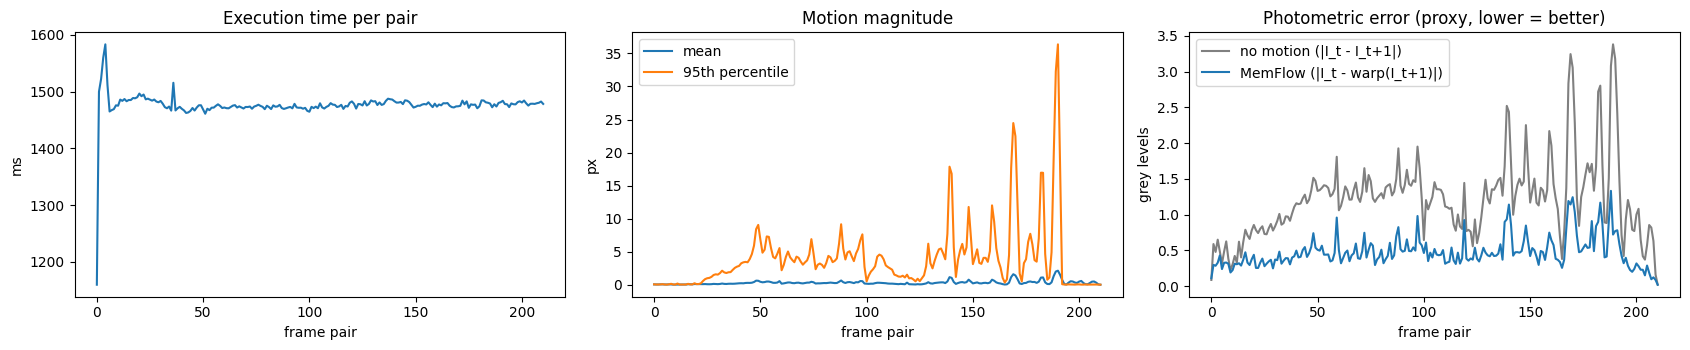

         pair  time_ms  mean_mag  p95_mag  photo_err  photo_zero_flow  temporal_var
count  211.00   211.00    211.00   211.00     211.00           211.00        210.00
mean   105.00  1476.60      0.31     3.99       0.48             1.21          0.09
std     61.05    25.04      0.31     5.07       0.22             0.56          0.11
min      0.00  1159.60      0.01     0.01       0.02             0.02          0.01
25%     52.50  1472.24      0.12     0.94       0.34             0.84          0.03
50%    105.00  1476.21      0.26     3.21       0.43             1.23          0.05
75%    157.50  1480.94      0.37     4.75       0.54             1.41          0.12
max    210.00  1583.41      2.13    36.37       1.33             3.38          0.56


In [37]:
# Per-pair statistics without ground truth
rows = []
for ti in range(n_pairs):
    f = flows[ti].astype(np.float32)
    mag = np.linalg.norm(f, axis=0)
    pe, base = photometric_error(VIDEO_FRAMES[ti], VIDEO_FRAMES[ti + 1], f)
    tv = float(np.abs(f - flows[ti - 1].astype(np.float32)).mean()) if ti > 0 else np.nan
    rows.append(dict(pair=ti, time_ms=times_ms[ti], mean_mag=float(mag.mean()), p95_mag=float(np.percentile(mag, 95)),
                     photo_err=pe, photo_zero_flow=base, temporal_var=tv))
import pandas as pd
per_pair = pd.DataFrame(rows)
per_pair.to_csv(f"{OUT}/per_pair.csv", index=False)

fig, ax = plt.subplots(1, 3, figsize=(17, 3.6))
ax[0].plot(per_pair.time_ms); ax[0].set_title("Execution time per pair"); ax[0].set_xlabel("frame pair"); ax[0].set_ylabel("ms")
ax[1].plot(per_pair.mean_mag, label="mean"); ax[1].plot(per_pair.p95_mag, label="95th percentile")
ax[1].set_title("Motion magnitude"); ax[1].set_xlabel("frame pair"); ax[1].set_ylabel("px"); ax[1].legend()
ax[2].plot(per_pair.photo_zero_flow, label="no motion (|I_t - I_t+1|)", color="grey")
ax[2].plot(per_pair.photo_err, label="MemFlow (|I_t - warp(I_t+1)|)")
ax[2].set_title("Photometric error (proxy, lower = better)"); ax[2].set_xlabel("frame pair"); ax[2].set_ylabel("grey levels"); ax[2].legend()
plt.tight_layout(); plt.savefig(f"{FIG}/per_pair_stats.png", dpi=130); plt.show()
print(per_pair.describe().round(2).to_string())

## **Création de la vidéo comparative**

Cette cellule associe chaque image d’entrée à sa visualisation du flux optique, côte à côte.
OpenCV ajoute des légendes et concatène horizontalement les deux images.
FFmpeg assemble ensuite ces paires en une vidéo MP4 au débit défini par FPS, avec un format de pixels compatible avec les lecteurs courants.
Le résultat memflow_result.mp4 permet d’observer simultanément la scène originale et le mouvement estimé par MemFlow.

In [38]:
COMBO = f"{WORK}/combo"
shutil.rmtree(COMBO, ignore_errors=True); os.makedirs(COMBO)
for ti in range(n_pairs):
    a = cv2.imread(frame_files[ti]); b = cv2.imread(f"{FLOW_PNG}/{ti:05d}.png")
    cv2.putText(a, f"Input  t={ti}", (10, 28), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 255), 2, cv2.LINE_AA)
    cv2.putText(b, f"MemFlow ({CHECKPOINT_STAGE})", (10, 28), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 0), 2, cv2.LINE_AA)
    cv2.imwrite(f"{COMBO}/{ti:05d}.jpg", cv2.hconcat([a, b]))
RESULT_VIDEO = f"{OUT}/memflow_result.mp4"
subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-framerate", str(FPS), "-i", f"{COMBO}/%05d.jpg",
                "-vf", "pad=ceil(iw/2)*2:ceil(ih/2)*2", "-c:v", "libx264", "-pix_fmt", "yuv420p", RESULT_VIDEO], check=True)
from IPython.display import HTML, display
from base64 import b64encode
if os.path.getsize(RESULT_VIDEO) < 40e6:
    display(HTML(f'<video width="100%" controls loop autoplay muted src="data:video/mp4;base64,{b64encode(open(RESULT_VIDEO, "rb").read()).decode()}"></video>'))

## **Visualisation du flux et de l’énergie du mouvement**

Cette cellule compare trois instants de la vidéo : début, paire sélectionnée et fin. Pour chacun, elle affiche l’image, le flux codé en couleurs et une carte thermique de magnitude. La couleur du flux représente principalement la direction, tandis que l’intensité/saturation représente la magnitude ; la normalisation par image impose de ne pas comparer directement les couleurs entre instants. La seconde figure superpose des flèches (vecteurs u,v) à l’image et calcule la magnitude moyenne pixel par pixel sur tout le clip. Cette dernière carte met en évidence les zones où le mouvement est récurrent.

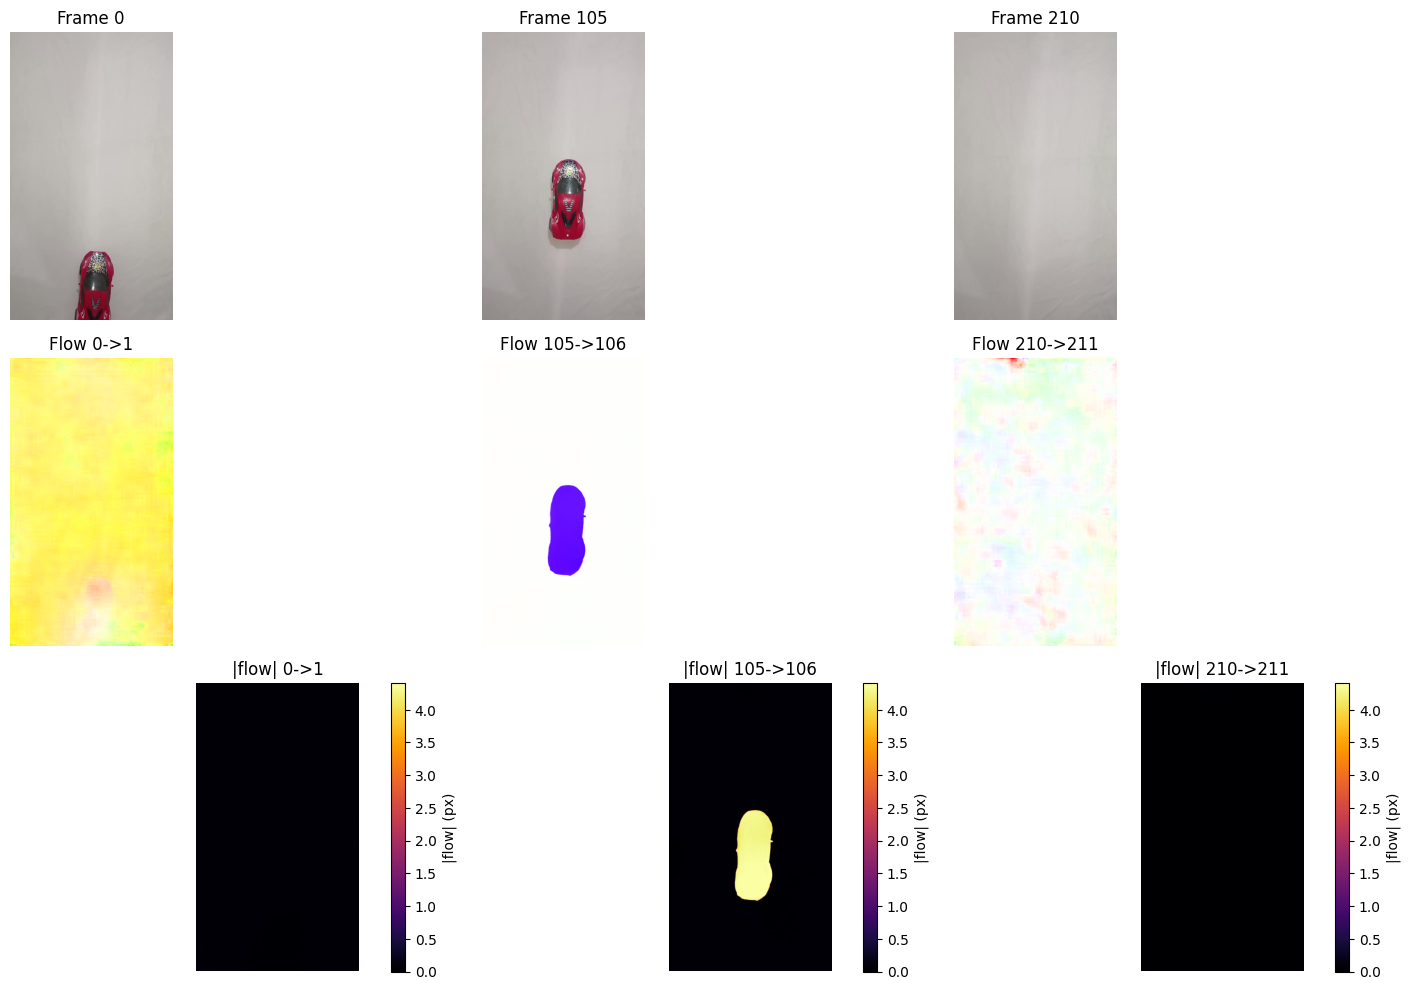

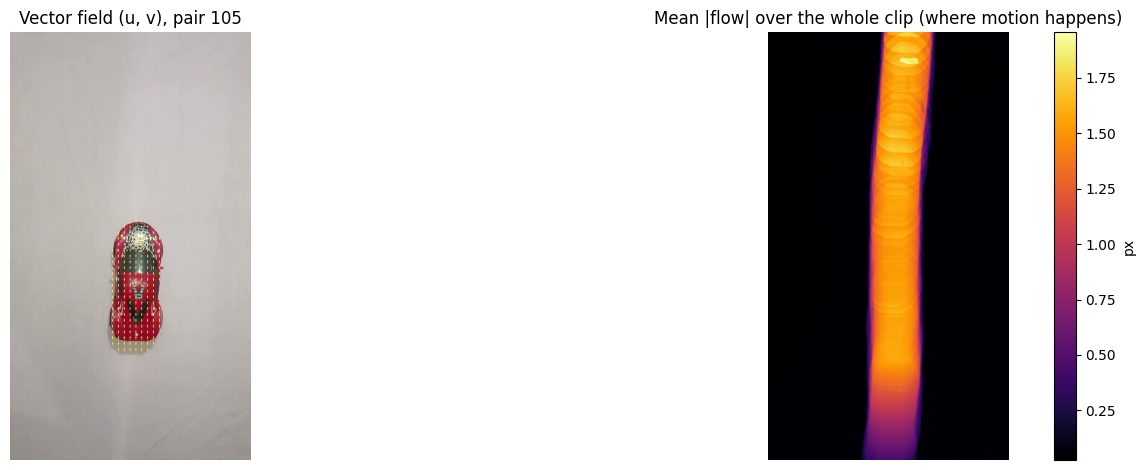

In [39]:
idx = sorted(set([0, ATT_PAIR, n_pairs - 1]))
vmax = float(np.percentile(np.linalg.norm(flows[idx].astype(np.float32), axis=1), 99.5))
fig, axes = plt.subplots(3, len(idx), figsize=(5.5 * len(idx), 10), squeeze=False)
for j, i in enumerate(idx):
    f = flows[i].astype(np.float32)
    axes[0, j].imshow(VIDEO_FRAMES[i]); axes[0, j].set_title(f"Frame {i}"); axes[0, j].axis("off")
    axes[1, j].imshow(flow_viz.flow_to_image(f.transpose(1, 2, 0))); axes[1, j].set_title(f"Flow {i}->{i+1}"); axes[1, j].axis("off")
    magnitude_heatmap(axes[2, j], f, f"|flow| {i}->{i+1}", vmax=vmax)
plt.tight_layout(); plt.savefig(f"{FIG}/frames_flow_heatmaps.png", dpi=130); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
f = flows[ATT_PAIR].astype(np.float32)
quiver_overlay(ax[0], VIDEO_FRAMES[ATT_PAIR], f, step=max(8, W0 // 40), title=f"Vector field (u, v), pair {ATT_PAIR}")
mean_mag_map = np.linalg.norm(flows.astype(np.float32), axis=1).mean(0)
im = ax[1].imshow(mean_mag_map, cmap="inferno"); ax[1].axis("off"); ax[1].set_title("Mean |flow| over the whole clip (where motion happens)")
plt.colorbar(im, ax=ax[1], fraction=0.03, label="px")
plt.tight_layout(); plt.savefig(f"{FIG}/vectors_and_motion_energy.png", dpi=130); plt.show()

## **Visualisation de l’attention portée à la mémoire**

MemFlow utilise un mécanisme d'attention pour consulter sa mémoire
(paper Eq. 2–4):
$$q=f_cW_q,\quad k=[f_cW_k;\,k_m],\quad v=[f_mW_v;\,v_m],\qquad f_{am}=f_m+\alpha\cdot\mathrm{Softmax}\!\Big(\tfrac{\log_{n_{avg}}(L+HW)}{\sqrt{D_k}}\,q k^\top\Big)v$$

Les informations utilisées proviennent de deux sources : la frame précédente, stockée dans la mémoire, et la frame actuelle.

Pour le pixel sélectionné (★), on visualise les zones auxquelles le modèle prête attention. On représente également, pour chaque pixel, la proportion d'attention accordée à la mémoire par rapport aux informations de la frame actuelle.


Cette cellule exploite les poids d’attention capturés pendant l’inférence de la paire ATT_PAIR. Les caractéristiques internes sont à résolution réduite (facteur 8), d’où le calcul des dimensions après padding et le redimensionnement des cartes pour les superposer à l’image.

Un pixel de requête est choisi automatiquement près du 98e percentile de magnitude, ou défini par QUERY_XY. Les cartes montrent les positions auxquelles ce pixel prête attention dans la mémoire (frame précédente) et dans l’image courante. La dernière carte représente, pour chaque position, la part totale d’attention provenant de la mémoire. Elle permet d’interpréter le mécanisme de mémoire, mais ne constitue pas à elle seule une mesure de précision.

Average share of attention on the memory: 0.50


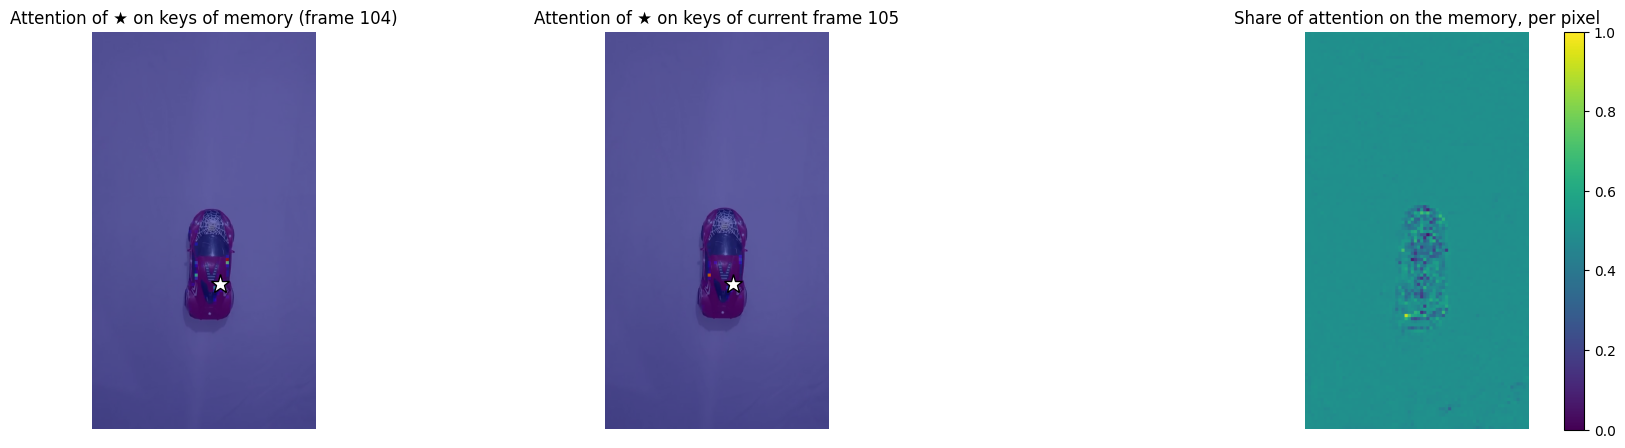

query pixel (x, y) = (330, 650) | keys: 18432 = memory + current


In [40]:
aff = extra.get("affinity")
assert aff is not None, "No attention captured (flash-attention installed, or ATT_PAIR = 0 / out of range)"
Hp, Wp = padder.pad(torch.zeros(1, 1, 1, H0, W0)).shape[-2:]
h8, w8 = Hp // 8, Wp // 8
HW = h8 * w8
n_keys = aff.shape[0]
has_mem = n_keys == 2 * HW
pad_l, pad_t = padder._pad[0], padder._pad[2]
f = flows[ATT_PAIR].astype(np.float32)
if QUERY_XY is None:
    mag = np.linalg.norm(f, axis=0)
    yq, xq = np.unravel_index(np.argmin(np.abs(mag - np.percentile(mag, 98))), mag.shape)
else:
    xq, yq = QUERY_XY
q_idx = ((yq + pad_t) // 8) * w8 + (xq + pad_l) // 8
a = aff[:, q_idx].numpy()

def up(m):  # 1/8-resolution to input resolution without padding
    m = cv2.resize(m.astype(np.float32), (Wp, Hp), interpolation=cv2.INTER_NEAREST)
    return m[pad_t:pad_t + H0, pad_l:pad_l + W0]

panels = []
if has_mem:
    panels.append((VIDEO_FRAMES[ATT_PAIR - 1], up(a[:HW].reshape(h8, w8)), f"keys of memory (frame {ATT_PAIR-1})"))
panels.append((VIDEO_FRAMES[ATT_PAIR], up(a[-HW:].reshape(h8, w8)), f"keys of current frame {ATT_PAIR}"))
fig, axes = plt.subplots(1, len(panels) + 1, figsize=(6 * (len(panels) + 1), 4.5))
for ax, (img, m, title) in zip(axes, panels):
    ax.imshow(img); ax.imshow(m, cmap="jet", alpha=0.55); ax.plot(xq, yq, "w*", ms=14, mec="k")
    ax.set_title("Attention of ★ on " + title); ax.axis("off")
if has_mem:
    mem_share = up(aff[:HW, :].sum(0).numpy().reshape(h8, w8))
    im = axes[-1].imshow(mem_share, cmap="viridis", vmin=0, vmax=1)
    axes[-1].set_title("Share of attention on the memory, per pixel"); axes[-1].axis("off")
    plt.colorbar(im, ax=axes[-1], fraction=0.03)
    print(f"Average share of attention on the memory: {mem_share.mean():.2f}")
plt.tight_layout(); plt.savefig(f"{FIG}/memory_attention.png", dpi=130); plt.show()
print("query pixel (x, y) =", (int(xq), int(yq)), "| keys:", n_keys, "=", "memory + current" if has_mem else "current only")

## **Raffinement itératif du flux par le GRU**

Cette cellule visualise les estimations du flux après différentes itérations du décodeur GRU. À chaque étape, le réseau prédit une correction résiduelle Δf qui est ajoutée au flux courant : f(k+1)=f(k)+Δf(k). La première figure montre l’évolution visuelle de l’estimation. La seconde trace la taille moyenne des corrections et la distance entre chaque estimation intermédiaire et l’estimation finale. Une diminution des corrections suggère une convergence. Le nombre d’itérations représente un compromis entre temps de calcul et raffinement.

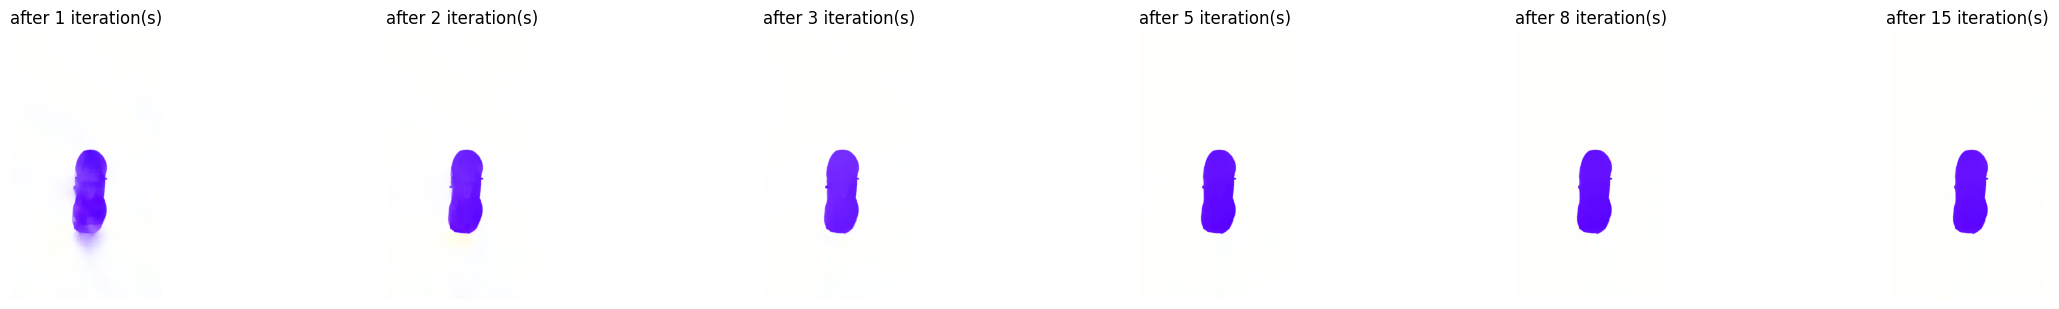

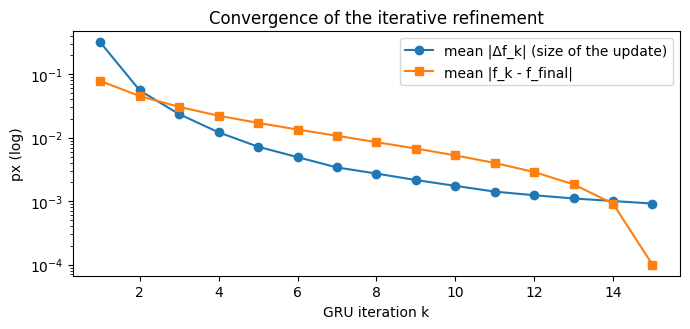

In [41]:
per_iter = extra["per_iter"]
show = [k for k in [1, 2, 3, 5, 8, ITERS] if k <= len(per_iter)]
fig, axes = plt.subplots(1, len(show), figsize=(4 * len(show), 3.2))
for ax, k in zip(axes, show):
    ax.imshow(flow_viz.flow_to_image(per_iter[k - 1].transpose(1, 2, 0))); ax.set_title(f"after {k} iteration(s)"); ax.axis("off")
plt.tight_layout(); plt.savefig(f"{FIG}/iterations_flow.png", dpi=130); plt.show()

final = per_iter[-1]
dist_to_final = [float(np.linalg.norm(p - final, axis=0).mean()) for p in per_iter]
update_size = [float(np.linalg.norm(per_iter[0], axis=0).mean())] + \
              [float(np.linalg.norm(per_iter[k] - per_iter[k - 1], axis=0).mean()) for k in range(1, len(per_iter))]
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.semilogy(range(1, len(per_iter) + 1), update_size, "o-", label="mean |Δf_k| (size of the update)")
ax.semilogy(range(1, len(per_iter) + 1), np.maximum(dist_to_final, 1e-4), "s-", label="mean |f_k - f_final|")
ax.set_xlabel("GRU iteration k"); ax.set_ylabel("px (log)"); ax.legend(); ax.set_title("Convergence of the iterative refinement")
plt.tight_layout(); plt.savefig(f"{FIG}/iterations_convergence.png", dpi=130); plt.show()

## **Étude du compromis entre nombre d’itérations, vitesse et qualité**

Cette cellule répète l’inférence sur un sous-ensemble limité de paires (STUDY_PAIRS) avec plusieurs profondeurs de décodage : 2, 5, 8, 15 et 24 itérations.

 Pour chaque configuration, elle mesure le temps moyen par paire, le débit FPS, l’erreur photométrique, l’écart au flux de référence produit avec le nombre d’itérations par défaut et la mémoire GPU maximale. Le graphique met en relation le temps de calcul et l’erreur photométrique. Il sert à choisir un compromis adapté à l’application, l’erreur photométrique reste toutefois un proxy sans vérité terrain.

 iters  ms_per_pair  fps  photo_err  mean_diff_vs_default_px  peak_mem_MB
     2       276.01 3.62       0.33                     0.02      3082.42
     5       554.83 1.80       0.33                     0.01      3082.42
     8       835.53 1.20       0.33                     0.00      3083.30
    15      1472.21 0.68       0.33                     0.00      3082.92
    24      2302.25 0.43       0.33                     0.00      3082.92


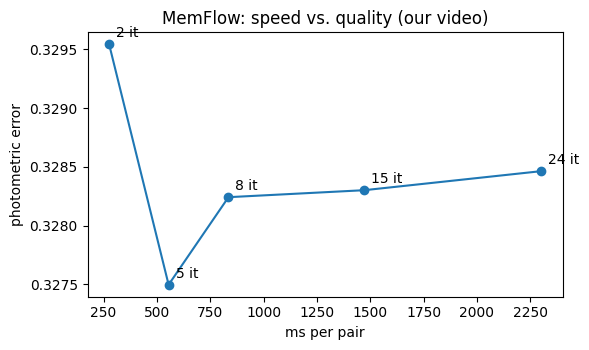

In [42]:
RUN_ITER_STUDY = True
STUDY_PAIRS = 40
iter_study = []
if RUN_ITER_STUDY:
    n_s = min(STUDY_PAIRS, n_pairs)
    for it in [2, 5, 8, 15, 24]:
        torch.cuda.reset_peak_memory_stats()
        fl, tms, _ = run_sequence(VIDEO_FRAMES, iters=it, n_pairs=n_s)
        pe = np.mean([photometric_error(VIDEO_FRAMES[i], VIDEO_FRAMES[i + 1], fl[i].astype(np.float32))[0] for i in range(n_s)])
        diff = np.mean([np.linalg.norm(fl[i].astype(np.float32) - flows[i].astype(np.float32), axis=0).mean() for i in range(n_s)])
        iter_study.append(dict(iters=it, ms_per_pair=float(tms[WARMUP:].mean()), fps=float(1000 / tms[WARMUP:].mean()),
                               photo_err=float(pe), mean_diff_vs_default_px=float(diff),
                               peak_mem_MB=torch.cuda.max_memory_allocated() / 2**20))
    iter_study = pd.DataFrame(iter_study)
    print(iter_study.round(2).to_string(index=False))
    fig, ax = plt.subplots(figsize=(6, 3.6))
    ax.plot(iter_study.ms_per_pair, iter_study.photo_err, "o-")
    for _, r in iter_study.iterrows():
        ax.annotate(f"{int(r.iters)} it", (r.ms_per_pair, r.photo_err), textcoords="offset points", xytext=(5, 5))
    ax.set_xlabel("ms per pair")
    ax.set_ylabel("photometric error")
    ax.set_title("MemFlow: speed vs. quality (our video)")
    plt.tight_layout()
    plt.savefig(f"{FIG}/iterations_speed_quality.png", dpi=130)
    plt.show()

## **Ablation : influence de la mémoire**

Une étude d’ablation consiste à désactiver un composant pour mesurer son influence. Ici, deux exécutions sont comparées sur les mêmes paires : MemFlow avec mémoire et MemFlow sans mémoire (mémoire vidée avant chaque paire). La fonction summarise calcule l’erreur photométrique, la variation temporelle du flux et le temps moyen. Le notebook calcule également la différence moyenne entre les deux champs de flux et affiche leurs cartes ainsi que la carte de différence. Cette expérience montre comment la mémoire modifie les prédictions,  une différence ne signifie pas automatiquement une amélioration, d’où l’intérêt de compléter cette comparaison par un benchmark avec vérité terrain.

              with_memory  without_memory
photo_err           0.405           0.400
temporal_var        0.045           0.051
ms_per_pair      1479.141        1069.334
mean |flow_with - flow_without| = 0.019 px over 80 pairs


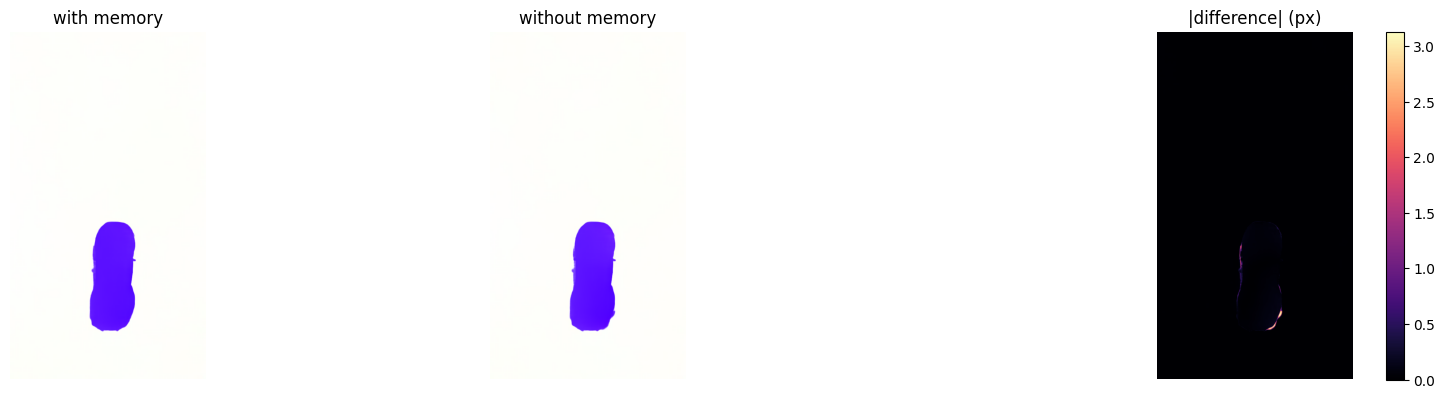

In [43]:
RUN_MEMORY_ABLATION = True
ablation = {}
if RUN_MEMORY_ABLATION:
    n_s = min(STUDY_PAIRS * 2, n_pairs)
    fl_nomem, t_nomem, _ = run_sequence(VIDEO_FRAMES, use_memory=False, n_pairs=n_s)
    def summarise(fl, tms):
        fl = [x.astype(np.float32) for x in fl]
        pe = np.mean([photometric_error(VIDEO_FRAMES[i], VIDEO_FRAMES[i + 1], fl[i])[0] for i in range(n_s)])
        tv = np.mean([np.abs(fl[i] - fl[i - 1]).mean() for i in range(1, n_s)])
        return dict(photo_err=float(pe), temporal_var=float(tv), ms_per_pair=float(np.mean(tms[WARMUP:])))
    ablation = {"with_memory": summarise(list(flows[:n_s]), times_ms[:n_s]), "without_memory": summarise(fl_nomem, t_nomem)}
    ablation["mean_diff_px"] = float(np.mean([np.linalg.norm(flows[i].astype(np.float32) - fl_nomem[i].astype(np.float32), axis=0).mean() for i in range(n_s)]))
    print(pd.DataFrame({k: v for k, v in ablation.items() if isinstance(v, dict)}).round(3).to_string())
    print(f"mean |flow_with - flow_without| = {ablation['mean_diff_px']:.3f} px over {n_s} pairs")
    i = min(ATT_PAIR, n_s - 1)
    d = np.linalg.norm(flows[i].astype(np.float32) - fl_nomem[i].astype(np.float32), axis=0)
    fig, ax = plt.subplots(1, 3, figsize=(17, 4))
    ax[0].imshow(flow_viz.flow_to_image(flows[i].astype(np.float32).transpose(1, 2, 0)))
    ax[0].set_title("with memory")
    ax[0].axis("off")
    ax[1].imshow(flow_viz.flow_to_image(fl_nomem[i].astype(np.float32).transpose(1, 2, 0)))
    ax[1].set_title("without memory")
    ax[1].axis("off")
    im = ax[2].imshow(d, cmap="magma")
    ax[2].set_title("|difference| (px)")
    ax[2].axis("off")
    plt.colorbar(im, ax=ax[2], fraction=0.03)
    plt.tight_layout()
    plt.savefig(f"{FIG}/memory_ablation.png", dpi=130)
    plt.show()

## **Évaluation sur le benchmark Middlebury avec vérité terrain**

La vidéo personnelle ne possède pas de flux optique de référence pixel par pixel, on ne peut donc pas calculer directement son EPE ou son Fl-all.

Cette cellule utilise huit séquences du benchmark Middlebury, qui fournit un flux optique annoté (ground truth).
Pour chaque séquence, MemFlow prédit le flux de la paire cible avec mémoire et sans mémoire, puis flow_metrics compare les prédictions à la référence.
L’**EPE** est l’erreur euclidienne moyenne en pixels
**Fl-all** est le pourcentage de pixels dont l’erreur dépasse simultanément 3 pixels et 5 % de la magnitude du flux réel.

- **EPE** $=\frac1N\sum_p\|f_{pred}(p)-f_{gt}(p)\|_2$ (pixels)
- **Fl-all** = % of pixels with EPE > 3 px **and** EPE > 5 % of $\|f_{gt}\|$ (KITTI definition)


               epe  fl_all  epe_no_memory  fl_all_no_memory  n_history_frames
Dimetrodon   0.149   0.000          0.149             0.000              0.00
Grove2       0.159   0.220          0.160             0.194              3.00
Grove3       0.419   2.083          0.424             2.042              3.00
Hydrangea    0.205   0.453          0.201             0.435              3.00
RubberWhale  0.135   0.106          0.136             0.103              3.00
Urban2       0.183   0.476          0.181             0.481              3.00
Urban3       0.228   0.729          0.250             0.692              3.00
Venus        0.234   0.075          0.234             0.075              0.00
mean         0.214   0.518          0.217             0.503              2.25


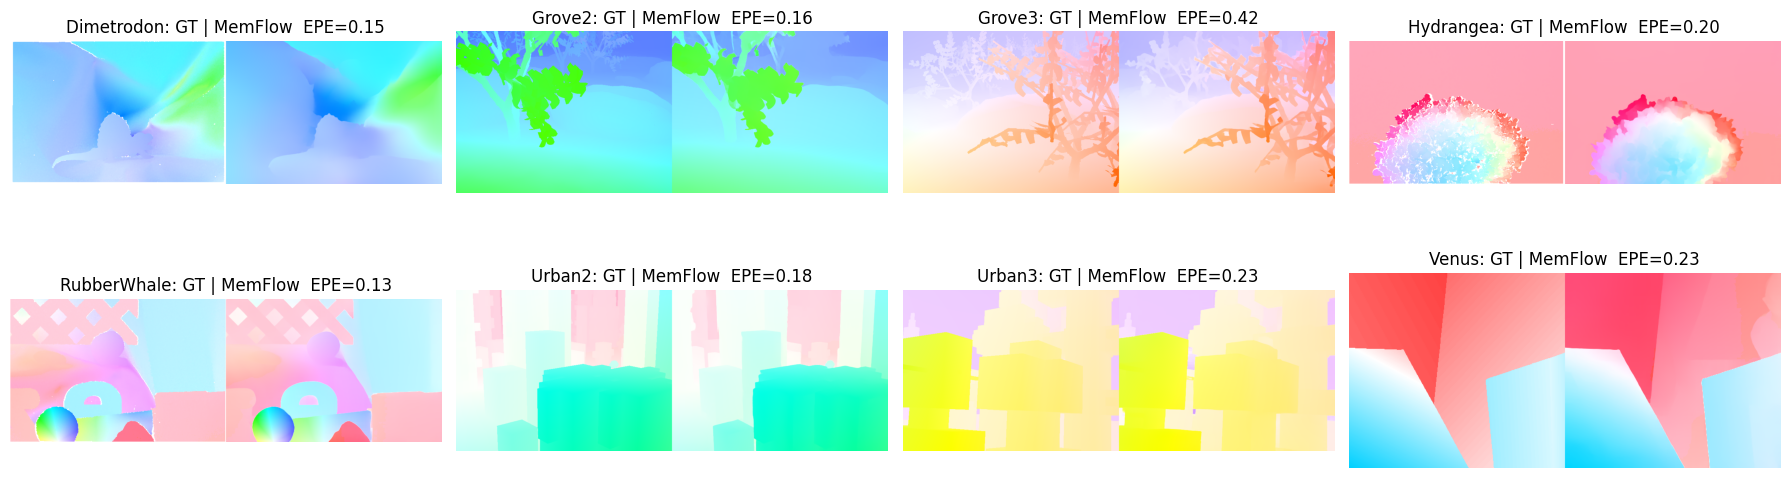

In [44]:
import glob
RUN_MIDDLEBURY = True
middlebury = {}
seqs = {}
if RUN_MIDDLEBURY:
    try:
        seqs = get_middlebury()
    except Exception as e:
        print("Middlebury indisponible -> section ignoree :", repr(e))
if seqs:
    for name, s in seqs.items():
        imgs = [cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB) for p in s["frames"]]
        res, preds = {}, {}
        for mode, use_mem in [("memory", True), ("no_memory", False)]:
            fl, _, _ = run_sequence(imgs, use_memory=use_mem, keep=True)
            preds[mode] = fl[-1]
            res[mode] = flow_metrics(fl[-1].astype(np.float32).transpose(1, 2, 0), s["gt"])
        middlebury[name] = dict(epe=res["memory"][0], fl_all=res["memory"][1],
                                epe_no_memory=res["no_memory"][0], fl_all_no_memory=res["no_memory"][1],
                                n_history_frames=len(imgs) - 2, last_pred=preds["memory"])
    mb = pd.DataFrame({k: {kk: vv for kk, vv in v.items() if kk != "last_pred"} for k, v in middlebury.items()}).T
    mb.loc["mean"] = mb.mean()
    print(mb.round(3).to_string())
    fig, axes = plt.subplots(2, 4, figsize=(18, 6))
    for ax, (name, s) in zip(axes.ravel(), seqs.items()):
        gt = s["gt"].copy()
        gt[np.abs(gt) > 1e9] = 0
        ax.imshow(np.hstack([flow_viz.flow_to_image(gt), flow_viz.flow_to_image(middlebury[name]["last_pred"].astype(np.float32).transpose(1, 2, 0))]))
        ax.set_title(f"{name}: GT | MemFlow  EPE={middlebury[name]['epe']:.2f}")
        ax.axis("off")
    plt.tight_layout()
    plt.savefig(f"{FIG}/middlebury.png", dpi=110)
    plt.show()

## **Export des résultats et génération du rapport**


Cette cellule rassemble les paramètres du modèle, les caractéristiques du clip, les temps d’exécution, la mémoire GPU, les statistiques de mouvement, les études d’itérations, l’ablation mémoire et les résultats Middlebury dans un dictionnaire Python. Le fichier results.json conserve ces résultats sous une forme structurée et réutilisable.

Le notebook crée ensuite une archive ZIP contenant le JSON, le CSV et les figures, puis déclenche son téléchargement depuis Colab. Les champs de flux bruts (flows.npy) restent séparés car ils peuvent être volumineux.



In [45]:
summary = dict(
    model="MemFlow", variant=MODEL, checkpoint=CKPT_NAME, iters=ITERS, gpu=GPU_NAME, n_params=N_PARAMS,
    alpha_memory_weight=float(model.update_block.aggregator.gamma), clip=CLIP_INFO,
    load_time_s=LOAD_TIME_S, total_time_s=TOTAL_TIME_S,
    time_ms_per_pair_mean=float(steady.mean()), time_ms_per_pair_median=float(np.median(steady)),
    time_ms_first_pair=float(times_ms[0]), pairs_per_s=float(1000 / steady.mean()),
    peak_mem_alloc_MB=PEAK_ALLOC_MB, peak_mem_reserved_MB=PEAK_RESERVED_MB,
    mean_flow_magnitude_px=float(per_pair.mean_mag.mean()), max_flow_magnitude_px=float(per_pair.p95_mag.max()),
    photometric_error_mean=float(per_pair.photo_err.mean()), photometric_zero_flow_mean=float(per_pair.photo_zero_flow.mean()),
    temporal_var_mean=float(per_pair.temporal_var.mean()), att_pair=int(ATT_PAIR),
    iter_study=iter_study.to_dict("records") if len(iter_study) else [],
    memory_ablation=ablation,
    middlebury={k: {kk: vv for kk, vv in v.items() if kk != "last_pred"} for k, v in middlebury.items()},
)
json.dump(summary, open(f"{OUT}/results.json", "w"), indent=1)
print(json.dumps({k: v for k, v in summary.items() if k not in ("iter_study", "middlebury", "clip")}, indent=1))

ZIP = f"/content/{TAG}_report.zip"
!cd "{OUT}" && zip -qr "{ZIP}" results.json per_pair.csv figures
from google.colab import files
files.download(ZIP)
print("Send this zip back (results.json + figures). The raw flows stay in", OUT)

{
 "model": "MemFlow",
 "variant": "MemFlowNet",
 "checkpoint": "MemFlowNet_sintel.pth",
 "iters": 15,
 "gpu": "Tesla T4",
 "n_params": 6273149,
 "alpha_memory_weight": -0.4330005645751953,
 "load_time_s": 0.4131068359999972,
 "total_time_s": 335.13442914100006,
 "time_ms_per_pair_mean": 1477.7920315000006,
 "time_ms_per_pair_median": 1476.1006395000322,
 "time_ms_first_pair": 1159.6008179999444,
 "pairs_per_s": 0.6766852024401375,
 "peak_mem_alloc_MB": 3794.197265625,
 "peak_mem_reserved_MB": 4876.0,
 "mean_flow_magnitude_px": 0.3130164052827628,
 "max_flow_magnitude_px": 36.37460708618164,
 "photometric_error_mean": 0.4754923227997894,
 "photometric_zero_flow_mean": 1.2126601903977412,
 "temporal_var_mean": 0.09437069005465933,
 "att_pair": 105,
 "memory_ablation": {
  "with_memory": {
   "photo_err": 0.4045353878289461,
   "temporal_var": 0.044842228293418884,
   "ms_per_pair": 1479.1414039610474
  },
  "without_memory": {
   "photo_err": 0.4004248518496752,
   "temporal_var": 0.051

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Send this zip back (results.json + figures). The raw flows stay in /content/drive/MyDrive/Analyse Video/presentation flow motion PROJET1/flow_optique/memflow
